# Moodle Activity Analysis (2019–2026)

## 01. Data preparation

In this notebook we load the Moodle event logs of all years (2019-2026), combine them into one table, separate students from teachers and count events and students per year.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

DATA_DIR = Path("tcs_dataset")
print(DATA_DIR.exists())

True


### 1. Load the data of each year

We read `events.parquet` for every year from 2019 to 2026 and add a `year` column, so that we know which year each row comes from.

In [2]:
frames = []

for year in range(2019, 2027):
    path = DATA_DIR / "data" / str(year) / "events.parquet"
    df = pd.read_parquet(path)
    df["year"] = year
    frames.append(df)
    print(year, df.shape)

2019 (68072, 10)
2020 (122142, 10)
2021 (183166, 10)
2022 (97830, 10)
2023 (121861, 10)
2024 (157788, 10)
2025 (112864, 10)
2026 (108649, 10)


### 2. Combine all years into one table

`pd.concat()` puts the eight tables one under another.

In [3]:
events = pd.concat(frames, ignore_index=True)
print(events.shape)

(972372, 10)


### 3. Separate students and teachers

Students have an `actor_id` that starts with `S`. The teacher has the `actor_id` with `T`.

In [4]:
students = events[events["actor_id"].astype(str).str.startswith("S")]
teachers = events[events["actor_id"] == "T"]

print("student events:", len(students))
print("teacher events:", len(teachers))
print("other:", len(events) - len(students) - len(teachers))

student events: 733090
teacher events: 239282
other: 0


### 4. Number of events and distinct students per year

In [5]:
summary = pd.DataFrame({
    "total_events": events.groupby("year").size(),
    "student_events": students.groupby("year").size(),
    "teacher_events": teachers.groupby("year").size(),
    "distinct_students": students.groupby("year")["actor_id"].nunique()
})
summary

,total_events,student_events,teacher_events,distinct_students
year,,,,
2019,68072,49036,19036,114
2020,122142,95219,26923,99
2021,183166,149697,33469,140
2022,97830,69629,28201,82
2023,121861,89316,32545,106
2024,157788,121967,35821,119
2025,112864,80127,32737,137
2026,108649,78099,30550,141


In [6]:
summary["events_per_student"] = (summary["student_events"] / summary["distinct_students"]).round(1)
summary.to_csv("yearly_summary.csv")
summary

,total_events,student_events,teacher_events,distinct_students,events_per_student
year,,,,,
2019,68072,49036,19036,114,430.1
2020,122142,95219,26923,99,961.8
2021,183166,149697,33469,140,1069.3
2022,97830,69629,28201,82,849.1
2023,121861,89316,32545,106,842.6
2024,157788,121967,35821,119,1024.9
2025,112864,80127,32737,137,584.9
2026,108649,78099,30550,141,553.9


### Initial observations

- Recorded student activity rose sharply during 2020–2021, increased again in 2024, then fell in 2025–2026.
- Total teacher events peaked in 2024. The number of teachers differs by year, so we compare events per teacher later.
- Some years have fewer distinct students in event logs than in `grades.csv`; these students may have no recorded events.

These initial totals motivate the normalised comparisons and activity-type analyses below.

## 02. Activity across years

#### Student and teacher events per year

In [7]:
activity = summary[["student_events", "teacher_events"]].copy()
activity

,student_events,teacher_events
year,,
2019,49036,19036
2020,95219,26923
2021,149697,33469
2022,69629,28201
2023,89316,32545
2024,121967,35821
2025,80127,32737
2026,78099,30550


#### Events per enrolled student

We read `course_runs.csv`, which has the number of enrolled students (`student_count`) for each year and divide the student events by it.

In [8]:
course_runs = pd.read_csv(DATA_DIR / "data" / "course_runs.csv")
course_runs["year"] = range(2019, 2027)
course_runs[["course_run_id", "year", "student_count", "teacher_count", "delivery_mode"]]

,course_run_id,year,student_count,teacher_count,delivery_mode
0,TCS_2019,2019,114,7,in_person
1,TCS_2020,2020,102,6,remote
2,TCS_2021,2021,142,7,remote
3,TCS_2022,2022,83,9,hybrid
4,TCS_2023,2023,106,8,hybrid
5,TCS_2024,2024,119,8,hybrid
6,TCS_2025,2025,137,6,in_person
7,TCS_2026,2026,142,6,in_person


In [9]:
activity = activity.join(course_runs.set_index("year")[["student_count"]])
activity["events_per_enrolled_student"] = (
    activity["student_events"] / activity["student_count"]
).round(1)
activity

,student_events,teacher_events,student_count,events_per_enrolled_student
year,,,,
2019,49036,19036,114,430.1
2020,95219,26923,102,933.5
2021,149697,33469,142,1054.2
2022,69629,28201,83,838.9
2023,89316,32545,106,842.6
2024,121967,35821,119,1024.9
2025,80127,32737,137,584.9
2026,78099,30550,142,550.0


In [10]:
activity["events_per_active_student"] = summary["events_per_student"]
activity.to_csv("activity_per_year.csv")
activity

,student_events,teacher_events,student_count,events_per_enrolled_student,events_per_active_student
year,,,,,
2019,49036,19036,114,430.1,430.1
2020,95219,26923,102,933.5,961.8
2021,149697,33469,142,1054.2,1069.3
2022,69629,28201,83,838.9,849.1
2023,89316,32545,106,842.6,842.6
2024,121967,35821,119,1024.9,1024.9
2025,80127,32737,137,584.9,584.9
2026,78099,30550,142,550.0,553.9


#### Student Moodle activity across years

We compare the average number of Moodle events per enrolled student from 2019 to 2026.

Dividing by the number of enrolled students allows us to compare course years with different cohort sizes.

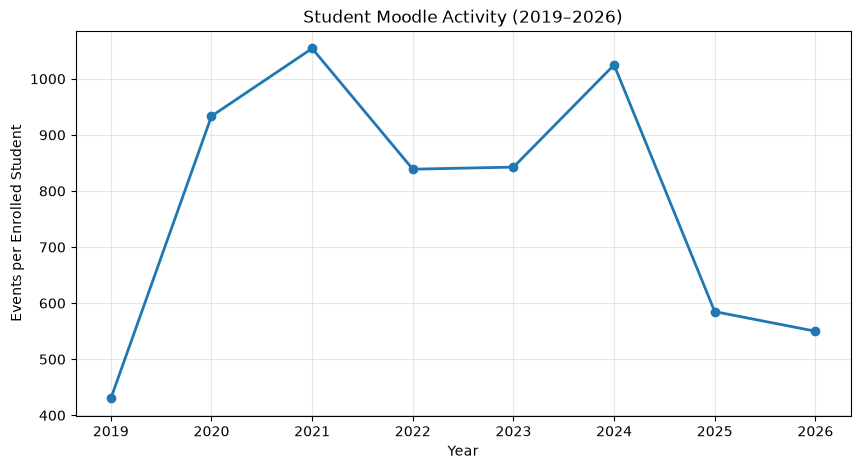

In [11]:
# Student activity per enrolled student
plt.figure(figsize=(10, 5))

plt.plot(
    activity.index,
    activity["events_per_enrolled_student"],
    marker="o",
    linewidth=2
)

plt.title("Student Moodle Activity (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Events per Enrolled Student")
plt.xticks(activity.index)
plt.grid(alpha=0.3)

plt.show()

#### Average and median activity per student

Yearly averages may hide differences between students. We compare the mean, median and 90th percentile of Moodle events per student to investigate whether activity changes affected most students or were influenced by particularly active students.

We also include students with no recorded events, using the enrolled student counts.

In [12]:
# Count Moodle events for each student in each year
student_event_counts = (
    students.groupby(["year", "actor_id"])
    .size()
    .rename("event_count")
    .reset_index()
)

# Calculate yearly activity statistics
distribution_results = []

for year in range(2019, 2027):

    counts = student_event_counts.loc[
        student_event_counts["year"] == year,
        "event_count"
    ].to_numpy()

    enrolled = course_runs.loc[
        course_runs["year"] == year,
        "student_count"
    ].iloc[0]

    # Include enrolled students with no recorded activity
    missing_students = enrolled - len(counts)
    assert missing_students >= 0

    counts = np.concatenate([
        counts,
        np.zeros(missing_students, dtype=int)
    ])

    distribution_results.append({
        "Year": year,
        "Mean": counts.mean(),
        "Median": np.median(counts),
        "90th percentile": np.percentile(counts, 90),
        "Maximum": counts.max()
    })

student_distribution = pd.DataFrame(distribution_results)

display(student_distribution.round(1))

,Year,Mean,Median,90th percentile,Maximum
0,2019,430.1,371.5,698.6,1911
1,2020,933.5,840.0,1560.6,3275
2,2021,1054.2,905.5,1946.5,10205
3,2022,838.9,813.0,1327.0,2549
4,2023,842.6,707.0,1458.0,3132
5,2024,1024.9,840.0,1633.6,4026
6,2025,584.9,524.0,1043.4,1630
7,2026,550.0,471.0,1039.2,3012


#### Teacher Moodle activity across years

We compare the total number of teacher Moodle events from 2019 to 2026 to examine how teacher activity changed across different teaching periods.

All teacher events are recorded under the shared identifier `T`, so the graph represents combined teacher activity rather than individual teachers.

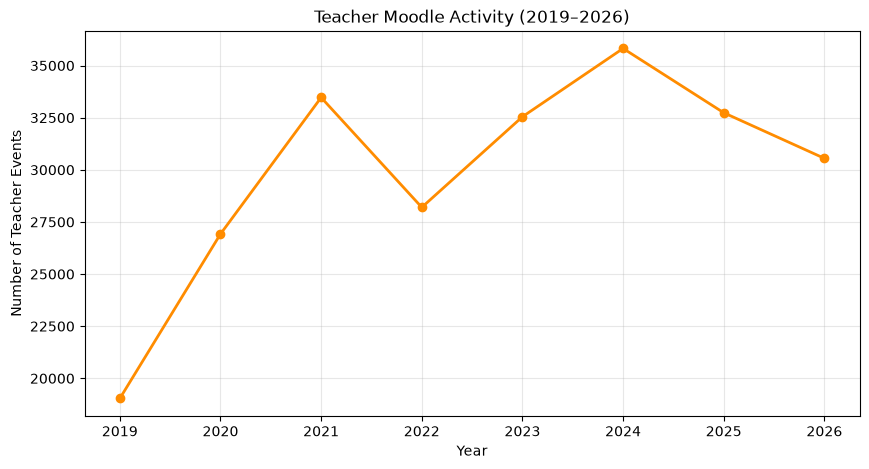

In [13]:
# Teacher Moodle activity by year
plt.figure(figsize=(10, 5))

plt.plot(
    activity.index,
    activity["teacher_events"],
    marker="o",
    linewidth=2,
    color="darkorange"
)

plt.title("Teacher Moodle Activity (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Number of Teacher Events")
plt.xticks(activity.index)
plt.grid(alpha=0.3)

plt.show()



### Teacher activity per teacher

To account for differences in teaching staff size, we calculate the average number of Moodle events per teacher for each year.

This helps us investigate whether the high teacher activity in 2024 was mainly related to having more teachers or to greater Moodle activity per teacher.


In [14]:
# Check teacher counts in each year
display(
    course_runs[
        ["course_run_id", "teacher_count"]
    ]
)

,course_run_id,teacher_count
0,TCS_2019,7
1,TCS_2020,6
2,TCS_2021,7
3,TCS_2022,9
4,TCS_2023,8
5,TCS_2024,8
6,TCS_2025,6
7,TCS_2026,6


In [15]:
# Match teacher counts to each year
teacher_counts = course_runs.set_index(
    course_runs["course_run_id"].str[-4:].astype(int)
)["teacher_count"]

activity["teacher_count"] = activity.index.map(teacher_counts)

# Average events per teacher
activity["events_per_teacher"] = (
    activity["teacher_events"] / activity["teacher_count"]
)

display(
    activity[["teacher_events", "teacher_count", "events_per_teacher"]].round(2)
)

,teacher_events,teacher_count,events_per_teacher
year,,,
2019,19036,7,2719.43
2020,26923,6,4487.17
2021,33469,7,4781.29
2022,28201,9,3133.44
2023,32545,8,4068.12
2024,35821,8,4477.62
2025,32737,6,5456.17
2026,30550,6,5091.67


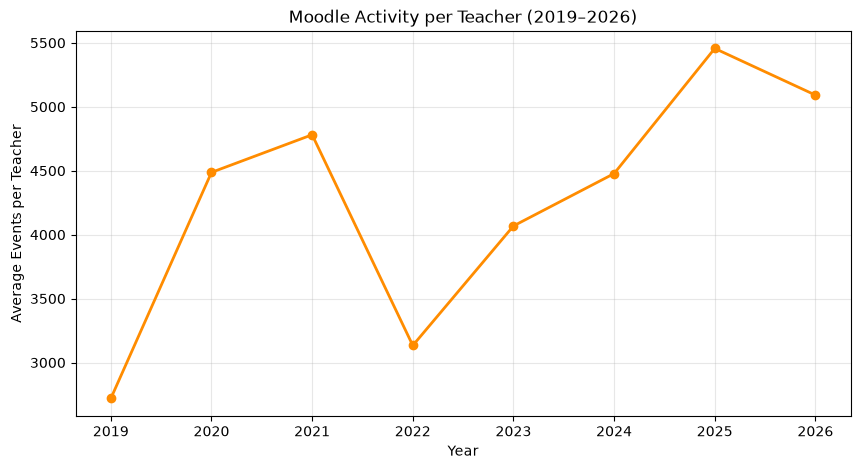

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(
    activity.index,
    activity["events_per_teacher"],
    marker="o",
    linewidth=2,
    color="darkorange"
)

plt.title("Moodle Activity per Teacher (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Average Events per Teacher")
plt.xticks(activity.index)
plt.grid(alpha=0.3)

plt.show()

### Interpretation of yearly activity

Student events per enrolled student rose during 2020–2021, fell afterward, increased again in 2024 and dropped in 2025–2026. The pattern is therefore not a steady post-pandemic decline.

Total teacher activity peaked in 2024, but average events per teacher peaked in 2025 because the teaching-team size changed. This shows why total event counts and counts adjusted for cohort or staff size tell different stories.

## 03. Activity types and weekly patterns

### 1. Activity types

In [17]:
students["event_name"].unique()

<ArrowStringArray>
[                                 'Course viewed',
                       'Grade user report viewed',
                            'User profile viewed',
                      'Course user report viewed',
                           'Course module viewed',
                               'User list viewed',
             'Course module instance list viewed',
                           'Quiz attempt started',
                            'Quiz attempt viewed',
                    'Quiz attempt summary viewed',
                   'Grade overview report viewed',
                                    'User graded',
                         'Quiz attempt submitted',
                          'Quiz attempt reviewed',
  'The status of the submission has been viewed.',
                        'Submission form viewed.',
                      'A file has been uploaded.',
                            'Submission created.',
              'An online text has been uploaded.',
            

In [18]:
# Checking which activities exist in each year
pd.crosstab(students["event_name"], students["year"])

year,2019,2020,2021,2022,2023,2024,2025,2026
event_name,,,,,,,,
A file has been uploaded.,932,1233,0,0,0,0,510,499
A submission has been submitted.,924,1233,0,0,0,0,510,499
An online text has been uploaded.,932,1233,0,0,0,0,510,499
BigBlueButton activity viewed,0,0,6364,2249,2032,0,0,0
BigBlueButton session created,0,0,275,73,85,0,0,0
BigBlueButton session joined,0,0,1917,801,496,513,391,324
BigBlueButtonBN activity viewed,0,2752,0,0,0,0,0,0
BigBlueButtonBN meeting created,0,98,0,0,0,0,0,0
BigBlueButtonBN meeting joined,0,774,0,0,0,0,0,0


### 2. Most Common Moodle Activities

We use `event_name` to find the five most common Moodle activities performed by students across all years.

In [19]:
top_activities = students["event_name"].value_counts().head(5)
top_activities

event_name
Course module viewed                             203637
Course viewed                                    179125
Quiz attempt viewed                               96242
Grade user report viewed                          40706
The status of the submission has been viewed.     32492
Name: count, dtype: int64

#### Observations:
The most common Moodle activities are viewing course materials and visiting the course page. Students also frequently view quiz attempts, check their grades, and check assignment submission statuses. This suggests that much of the recorded Moodle activity is related to accessing course information and monitoring learning progress.

### 3. Activity Comparison Across Years (most frequent activities)

We compare the five most common student activities from 2019 to 2026. To account for differences in the number of enrolled students, we calculate the average number of events per student for each year.

In [20]:
activity_counts = pd.crosstab(students["year"], students["event_name"])
activity_counts = activity_counts[top_activities.index]
activity_counts

student_counts = course_runs.set_index("year")["student_count"]
activity_per_student = activity_counts.div(student_counts, axis=0)
activity_per_student.round(2)

event_name,Course module viewed,Course viewed,Quiz attempt viewed,Grade user report viewed,The status of the submission has been viewed.
year,,,,,
2019,78.54,142.06,6.04,43.58,80.36
2020,283.43,217.75,64.09,46.45,100.04
2021,264.42,241.82,212.19,46.33,0.00
2022,225.40,189.19,205.16,32.80,0.00
2023,232.76,213.73,166.41,37.08,11.79
2024,245.53,221.24,174.96,46.29,7.66
2025,193.96,159.04,12.98,42.86,42.16
2026,204.61,140.20,11.41,44.98,36.54


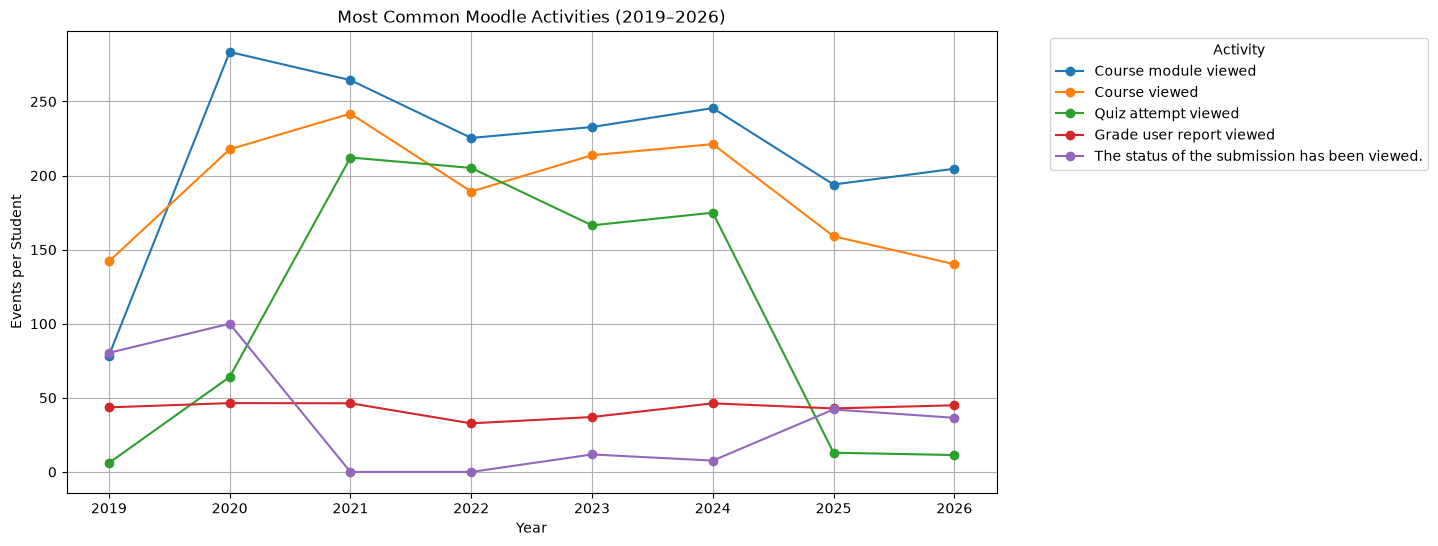

In [21]:
activity_per_student.plot(kind="line", marker="o", figsize=(12, 6))

plt.title("Most Common Moodle Activities (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Events per Student")
plt.legend(title="Activity", bbox_to_anchor=(1.05, 1))
plt.grid()
plt.show()

#### Observations
Moodle activity changed noticeably between 2019 and 2026. Viewing course modules and course pages increased during 2020–2021, when teaching moved online. Quiz attempt views were especially frequent between 2021 and 2024, but decreased significantly in 2025. Grade report views remained relatively stable throughout the years. These changes may be related to the transition to online learning, but changes in course activities and Moodle resources could also have influenced the results.

### 4. Weekly Activity Patterns

We analyze the number of student Moodle events during each week of the semester to see when students are most active.

In [22]:
weekly_students = students.copy()
start_dates = course_runs.set_index("year")["course_start_date"]
weekly_students["semester_start"] = weekly_students["year"].map(start_dates)
weekly_students["event_time"] = pd.to_datetime(weekly_students["event_time"], utc=True)
weekly_students["semester_start"] = pd.to_datetime(weekly_students["semester_start"], utc=True)
weekly_students["week"] = ((weekly_students["event_time"] - weekly_students["semester_start"]).dt.days // 7) + 1

weekly_activity = pd.crosstab(weekly_students["week"], weekly_students["year"])
weekly_activity.head(10)

year,2019,2020,2021,2022,2023,2024,2025,2026
week,,,,,,,,
0,0,0,0,0,12,4,7,0
1,827,0,1128,698,1120,1329,1342,1549
2,1475,928,2685,1000,1472,1639,1514,1366
3,1947,642,3015,1176,1511,3204,1600,2354
4,2914,1787,4828,2202,3406,5140,2832,1761
5,3293,3000,6705,2110,5399,6850,4223,3398
6,2781,5803,8720,4282,6855,9114,3641,3173
7,3359,4560,7367,4392,5940,7907,3741,3092
8,3268,6290,6414,3672,5101,6808,3602,2943


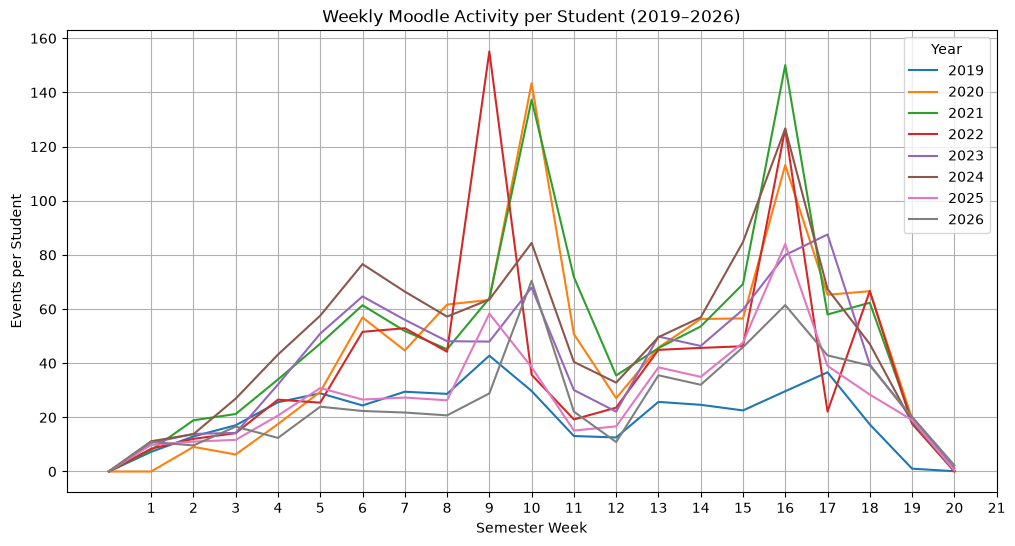

In [23]:
weekly_per_student = weekly_activity.div(student_counts, axis=1)

weekly_per_student.plot(kind="line", figsize=(12, 6))
plt.title("Weekly Moodle Activity per Student (2019–2026)")
plt.xlabel("Semester Week")
plt.ylabel("Events per Student")
plt.xticks(range(1, 22))
plt.legend(title="Year")
plt.grid()
plt.show()

In [24]:
# Checking approximately when midterms and exams are to see whether the spikes of activity are caused by them (using year 2021)
calendar_2021 = pd.read_csv("tcs_dataset/data/2021/calendar.csv")
important_events = calendar_2021[calendar_2021["activity_type"].isin(["midterm_exam", "final_exam"])]

calendar_events = important_events.copy()
calendar_events["date"] = calendar_events["start_time"].fillna(calendar_events["end_time"])
calendar_events["date"] = pd.to_datetime(calendar_events["date"], utc=True)
semester_start = pd.to_datetime(start_dates.loc[2021], utc=True)
calendar_events["week"] = ((calendar_events["date"] - semester_start).dt.days // 7) + 1
calendar_events[["activity_type", "activity_name", "week"]]

,activity_type,activity_name,week
56,midterm_exam,midterm_attempt_1,10
57,midterm_exam,midterm_attempt_2,16
58,midterm_exam,midterm_attempt_3,18
59,final_exam,final_attempt_1,16
60,final_exam,final_attempt_2,18
61,final_exam,final_attempt_3,19


#### Observations

Weekly Moodle activity follows a similar pattern across most years. Activity generally increases during the first weeks of the semester, with noticeable peaks around weeks 9–10 and 16–17. The 2021 course calendar shows that these peaks correspond to the midterm and final exam periods. Overall, activity was generally lower in 2019, 2023, 2025, and 2026 compared to the other years. After the final exams, activity drops sharply toward the end of the semester.


## 04. Changes in Activity Types (2019–2026)

We investigate how different types of Moodle activity changed between 2019 and 2026.

Since students and teachers use Moodle for different purposes, we analyse their activities separately. We group related events into broader categories to make comparisons across years easier.

We compare both the proportions of activity types and their frequency, taking differences in student and teacher numbers into account.

In [25]:
# Count event types separately for students and teachers
student_event_types = students["event_name"].value_counts()
teacher_event_types = teachers["event_name"].value_counts()

# Combine counts into one table
event_type_summary = pd.DataFrame({
    "Student events": student_event_types,
    "Teacher events": teacher_event_types
}).fillna(0).astype(int)

# Show all event types, most frequent first
event_type_summary["Total"] = (
    event_type_summary["Student events"]
    + event_type_summary["Teacher events"]
)

event_type_summary = event_type_summary.sort_values(
    "Total", ascending=False
)

display(event_type_summary)

print("Number of event types:", len(event_type_summary))


,Student events,Teacher events,Total
event_name,,,
Course module viewed,203637,29772,233409
Course viewed,179125,18761,197886
Quiz attempt viewed,96242,1929,98171
Grade user report viewed,40706,716,41422
The status of the submission has been viewed.,32492,4498,36990
...,...,...,...
Course copy created,0,1,1
Dates report viewed,0,1,1
Discussion deleted,0,1,1


Number of event types: 144


In [26]:
# Display event names in groups of 40
for start in range(0, len(event_type_summary), 40):
    print(f"\nEvent types {start + 1}–{min(start + 40, len(event_type_summary))}")

    display(
        event_type_summary.iloc[start:start + 40]
    )



Event types 1–40


,Student events,Teacher events,Total
event_name,,,
Course module viewed,203637,29772,233409
Course viewed,179125,18761,197886
Quiz attempt viewed,96242,1929,98171
Grade user report viewed,40706,716,41422
The status of the submission has been viewed.,32492,4498,36990
User graded,5404,30850,36254
Quiz attempt reviewed,27766,5651,33417
Course user report viewed,31810,3,31813
Quiz attempt updated,18512,121,18633



Event types 41–80


,Student events,Teacher events,Total
event_name,,,
Submission updated.,1486,0,1486
User list viewed,272,1192,1464
Quiz edit page viewed,0,1407,1407
BigBlueButtonBN meeting joined,774,116,890
Question moved,0,890,890
BigBlueButtonBN meeting left,642,190,832
Log report viewed,0,770,770
User profile viewed,298,399,697
Course activity completion updated,609,14,623



Event types 81–120


,Student events,Teacher events,Total
event_name,,,
Question category updated,0,51,51
Calendar event deleted,0,50,50
Response submitted,38,0,38
All the submissions are being downloaded.,0,38,38
Remove submission confirmation viewed.,33,0,33
Comment created,31,0,31
The status of the submission has been updated.,30,0,30
Quiz grade updated,0,26,26
OpenDocument grade exported,0,23,23



Event types 121–144


,Student events,Teacher events,Total
event_name,,,
Enrolment instance updated,0,3,3
User report viewed,3,0,3
Course reset ended,0,3,3
Discussion subscription deleted,3,0,3
Course reset started,0,3,3
Page break created,0,3,3
Grade item deleted,0,2,2
Comment deleted,2,0,2
User log report viewed,0,2,2


### 4.1 Student activity categories

We first classify student Moodle events into meaningful activity categories, such as course navigation, quizzes, assignments, online learning, grades and feedback, and discussions.

In [27]:
# Classify student Moodle activities
def classify_student_event(event):
    event = str(event).lower()

    if "bigbluebutton" in event or "recording" in event:
        return "Online learning"

    if "quiz" in event or "question" in event or "choice answer" in event:
        return "Quizzes"

    if "submission" in event or "uploaded" in event:
        return "Assignments"

    if (
        "grade" in event
        or "feedback" in event
        or event == "response submitted"
    ):
        return "Grades and feedback"

    if (
        "discussion" in event
        or "post " in event
        or "comment" in event
        or "content has been posted" in event
    ):
        return "Discussions"

    if (
        "course viewed" in event
        or "course module viewed" in event
        or "course module instance list viewed" in event
        or "course searched" in event
    ):
        return "Course navigation"

    return "Other"

# Apply the updated classification
students["activity_category"] = (
    students["event_name"].apply(classify_student_event)
)

display(
    students.groupby("activity_category").size()
    .sort_values(ascending=False)
)

activity_category
Course navigation      384969
Quizzes                168426
Grades and feedback     53690
Assignments             52335
Other                   32993
Online learning         27879
Discussions             12798
dtype: int64

In [28]:
# Show event names and their assigned categories
student_category_check = (
    students[["event_name", "activity_category"]]
    .drop_duplicates()
    .sort_values(["activity_category", "event_name"])
)

display(student_category_check)

,event_name,activity_category
4268,A file has been uploaded.,Assignments
4272,A submission has been submitted.,Assignments
4270,An online text has been uploaded.,Assignments
80341,Remove submission confirmation viewed.,Assignments
4269,Submission created.,Assignments
3991,Submission form viewed.,Assignments
788712,Submission removed.,Assignments
7143,Submission updated.,Assignments
80343,The status of the submission has been updated.,Assignments
2982,The status of the submission has been viewed.,Assignments


#### Student activity distribution across years

We calculate the percentage of student Moodle events belonging to each activity category in every year.

This allows us to examine how the composition of student activity changed between 2019 and 2026, independently of differences in total event counts.

In [29]:
# Count student events by year and activity category
student_category_counts = pd.crosstab(
    students["year"],
    students["activity_category"]
)

# Convert counts to percentages within each year
student_category_pct = (
    student_category_counts
    .div(student_category_counts.sum(axis=1), axis=0)
    * 100
)

display(student_category_pct.round(1))

# Verify that percentages add up to 100% for each year
print("\nYearly percentage totals:")
display(student_category_pct.sum(axis=1).round(1))


activity_category,Assignments,Course navigation,Discussions,Grades and feedback,Online learning,Other,Quizzes
year,,,,,,,
2019,30.2,52.0,0.5,11.7,0.0,1.5,4.1
2020,18.8,54.0,1.4,7.4,5.0,3.5,10.0
2021,0.0,48.3,2.0,4.8,7.5,7.7,29.8
2022,0.0,49.6,1.7,4.8,5.7,1.6,36.6
2023,1.4,53.1,1.2,5.9,4.1,4.7,29.6
2024,0.7,45.8,1.8,5.7,1.1,6.2,38.8
2025,11.3,60.9,2.5,11.2,1.8,3.5,8.7
2026,10.8,63.0,2.4,11.7,1.9,2.3,7.9



Yearly percentage totals:


year
2019    100.0
2020    100.0
2021    100.0
2022    100.0
2023    100.0
2024    100.0
2025    100.0
2026    100.0
dtype: float64

#### Visualisation of student activity categories

We use a 100% stacked bar chart to compare the proportions of different student activity categories across the eight course years.

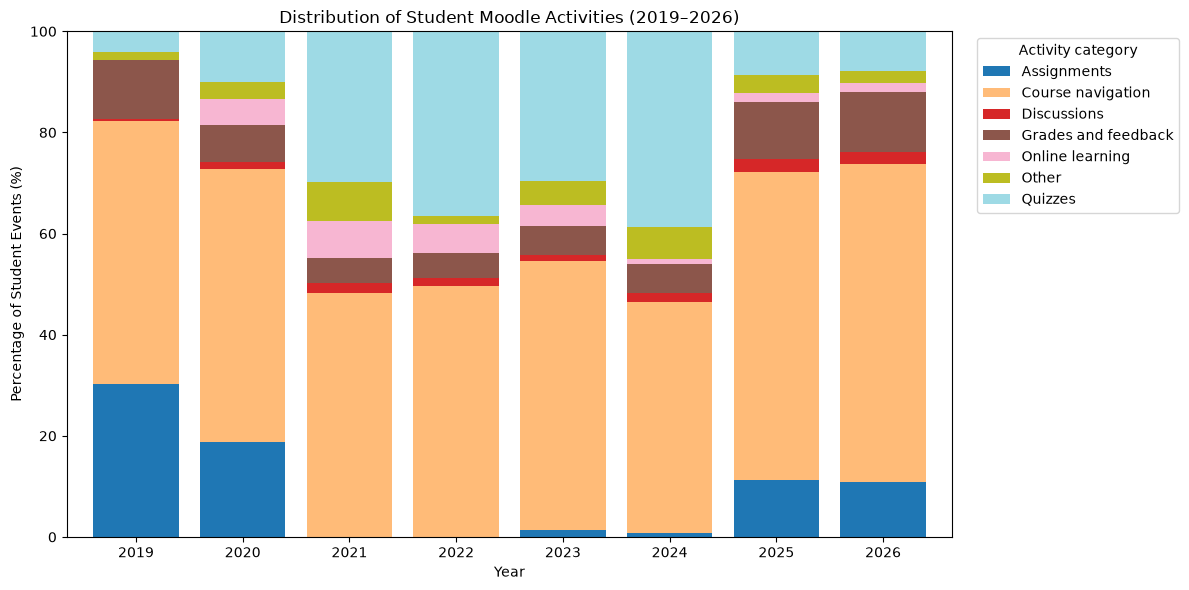

In [30]:
# Visualise the distribution of student activity categories
ax = student_category_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20",
    width=0.8
)

plt.title("Distribution of Student Moodle Activities (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Percentage of Student Events (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.legend(
    title="Activity category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


### Interpretation

Student activity categories changed substantially. Assignment events accounted for 30.2% of events in 2019 but almost disappeared in 2021–2022. Meanwhile, quizzes grew from 4.1% in 2019 to 38.8% in 2024, then fell to 8.7% in 2025. Course navigation accounted for a larger share in 2025–2026, and online learning events were more prominent during remote teaching.

These percentages show how the *composition* of recorded events changed; the next comparison examines their frequency per enrolled student.

#### Student activity categories per enrolled student

Percentages show the distribution of Moodle activity but not how frequently each activity occurred.

To compare activity levels across years with different cohort sizes, we calculate the number of events in each category per enrolled student.


In [31]:
# Get enrolled student counts for each year
enrolled_counts = course_runs.set_index(
    course_runs["course_run_id"].str[-4:].astype(int)
)["student_count"]

# Calculate category events per enrolled student
student_category_per_student = student_category_counts.div(
    enrolled_counts,
    axis=0
)

display(student_category_per_student.round(1))

activity_category,Assignments,Course navigation,Discussions,Grades and feedback,Online learning,Other,Quizzes
year,,,,,,,
2019,130.1,223.5,2.1,50.4,0.0,6.3,17.7
2020,175.2,504.1,12.9,68.8,46.7,32.3,93.5
2021,0.0,509.1,20.6,51.1,78.7,80.8,313.9
2022,0.0,415.9,14.2,40.7,48.2,13.3,306.7
2023,11.8,447.5,10.0,49.7,34.7,39.4,249.5
2024,7.7,469.1,18.1,57.9,11.2,63.6,397.3
2025,65.9,356.3,14.9,65.6,10.6,20.7,50.9
2026,59.5,346.4,13.2,64.4,10.4,12.8,43.3


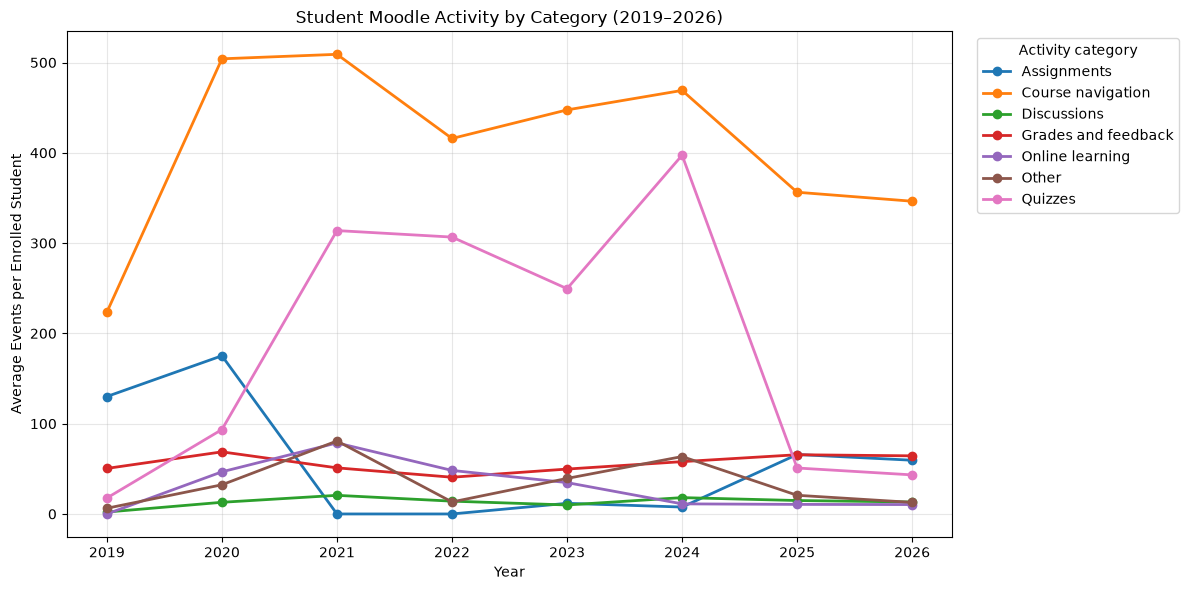

In [32]:
# Visualise student activity frequency by category
ax = student_category_per_student.plot(
    kind="line",
    marker="o",
    figsize=(12, 6),
    linewidth=2
)

plt.title("Student Moodle Activity by Category (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Average Events per Enrolled Student")
plt.xticks(student_category_per_student.index)
plt.grid(alpha=0.3)

plt.legend(
    title="Activity category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### Interpretation

Changes in proportions were accompanied by large differences in recorded event frequency. Quiz events rose from 17.7 per enrolled student in 2019 to 397.3 in 2024, then fell to 50.9 in 2025. Assignment events almost disappeared in 2021–2022 and returned in later years.

Course navigation accounted for a greater *share* of activity in 2025–2026, even though navigation events per student were lower than during 2020–2024. This distinction matters when interpreting percentage charts.

#### Investigating changes in quiz events

Quiz events increased substantially before 2025, particularly in 2024. However, different quiz events may represent different numbers of interactions within a single attempt.

We examine individual quiz event types across years to determine which events contributed most to the observed changes.


In [33]:
# Compare individual quiz event types across years
quiz_events = students[
    students["activity_category"] == "Quizzes"
]

quiz_by_year = pd.crosstab(
    quiz_events["year"],
    quiz_events["event_name"]
)

display(quiz_by_year)

event_name,Choice answer added,Choice answer deleted,Quiz attempt reviewed,Quiz attempt started,Quiz attempt submitted,Quiz attempt summary viewed,Quiz attempt updated,Quiz attempt viewed,Quiz submitted automatically
year,,,,,,,,,
2019,0,0,512,242,214,358,0,689,0
2020,0,0,1576,417,393,614,0,6537,0
2021,298,3,8848,1790,1479,2021,0,30131,0
2022,308,0,4580,1264,979,1294,0,17028,0
2023,0,0,4613,1487,1167,1542,0,17639,0
2024,0,0,4599,1826,1467,1846,16725,20820,0
2025,0,0,1772,831,734,933,927,1778,0
2026,0,0,1266,821,726,849,860,1620,3


### Interpretation

The 2024 increase in quiz activity was partly driven by `Quiz attempt updated` (16,725 recorded events), which was not recorded in previous years. Other quiz interactions also increased, while `Quiz attempt viewed` fell sharply from 20,820 events in 2024 to 1,778 in 2025.

The next check tests whether the decline in recorded interactions coincided with lower quiz participation.

#### Quiz participation across years

To distinguish changes in quiz participation from changes in event frequency, we calculate the percentage of enrolled students who submitted at least one quiz attempt in each year.


In [34]:
# Count students who submitted at least one quiz attempt
quiz_participants = (
    students[
        students["event_name"] == "Quiz attempt submitted"
    ]
    .groupby("year")["actor_id"]
    .nunique()
)

# Compare with total enrolled students
quiz_participation = pd.DataFrame({
    "Enrolled students": enrolled_counts,
    "Quiz participants": quiz_participants
}).fillna(0)

quiz_participation["Participation (%)"] = (
    quiz_participation["Quiz participants"]
    / quiz_participation["Enrolled students"]
    * 100
)

display(quiz_participation.round(1))

,Enrolled students,Quiz participants,Participation (%)
2019,114,110,96.5
2020,102,98,96.1
2021,142,136,95.8
2022,83,79,95.2
2023,106,101,95.3
2024,119,115,96.6
2025,137,133,97.1
2026,142,136,95.8


### Interpretation

Approximately 95–97% of enrolled students submitted at least one quiz attempt in every year. Yet quiz-event frequency varied greatly, including the sharp decline after 2024.

**Key distinction:** fewer logged quiz interactions did not mean that fewer students participated in quizzes. Event frequency should not be confused with participation.

### 4.2 Teacher activity categories

We investigate how teachers' Moodle activities changed between 2019 and 2026.

Teacher events are grouped into categories such as course navigation, grading and assessment, quiz management, course management, online teaching and discussions.

This allows us to compare how Moodle was used for teaching and course administration across years.


In [35]:
# Classify teacher Moodle events
def classify_teacher_event(event):
    event = str(event).lower()

    if "bigbluebutton" in event or "recording" in event:
        return "Online teaching"

    if (
        "grading" in event
        or "graded" in event
        or "grade" in event
        or "submission" in event
        or "feedback" in event
    ):
        return "Grading and assessment"

    if (
        "quiz" in event
        or "question" in event
        or "choice" in event
    ):
        return "Quiz management"

    if (
        "discussion" in event
        or "post " in event
        or "comment" in event
    ):
        return "Discussions"

    if event in [
        "course viewed",
        "course module viewed",
        "course module instance list viewed"
    ]:
        return "Course navigation"
    
    if (
        "module" in event
        or "course section" in event
        or "enrol" in event
        or "role" in event
        or "group" in event
        or "calendar event" in event
        or "course updated" in event
    ):
        return "Course management"

    return "Other"

# Apply classification
teachers = teachers.copy()

teachers["activity_category"] = (
    teachers["event_name"].apply(classify_teacher_event)
)

display(teachers["activity_category"].value_counts())

activity_category
Grading and assessment    117553
Course navigation          49695
Quiz management            43315
Course management          11658
Other                      11452
Online teaching             4159
Discussions                 1450
Name: count, dtype: int64

In [36]:
# Show all teacher event types grouped by category
teacher_category_check = (
    teachers[["event_name", "activity_category"]]
    .drop_duplicates()
    .sort_values(["activity_category", "event_name"])
)

for category in sorted(teacher_category_check["activity_category"].unique()):
    print(f"\n{category}")

    display(
        teacher_category_check[
            teacher_category_check["activity_category"] == category
        ].reset_index(drop=True)
    )


Course management


,event_name,activity_category
0,Calendar event created,Course management
1,Calendar event deleted,Course management
2,Calendar event updated,Course management
3,Course module created,Course management
4,Course module deleted,Course management
5,Course module updated,Course management
6,Course section created,Course management
7,Course section updated,Course management
8,Course updated,Course management
9,Enrolment instance created,Course management



Course navigation


,event_name,activity_category
0,Course module instance list viewed,Course navigation
1,Course module viewed,Course navigation
2,Course viewed,Course navigation



Discussions


,event_name,activity_category
0,Discussion created,Discussions
1,Discussion deleted,Discussions
2,Discussion updated,Discussions
3,Post created,Discussions
4,Post deleted,Discussions
5,Post updated,Discussions


... (4 outputs left out)


Other


,event_name,activity_category
0,Accessibility report viewed,Other
1,Activity report viewed,Other
2,Batch set workflow state viewed.,Other
3,Course activity completion updated,Other
4,Course copy created,Other
5,Course reset ended,Other
6,Course reset started,Other
7,Course searched,Other
8,Course user report viewed,Other
9,Dates report viewed,Other



Quiz management


,event_name,activity_category
0,Choice answer added,Quiz management
1,Choice answer deleted,Quiz management
2,Choice report viewed,Quiz management
3,Question category created,Quiz management
4,Question category deleted,Quiz management
5,Question category moved,Quiz management
6,Question category updated,Quiz management
7,Question category viewed,Quiz management
8,Question created,Quiz management
9,Question deleted,Quiz management


#### Teacher activity distribution across years

We calculate the percentage of teacher Moodle events belonging to each activity category from 2019 to 2026.

This allows us to examine how the types of activities performed by teachers changed over time, independently of differences in total event counts.

In [37]:
# Count teacher events by year and activity category
teacher_category_counts = pd.crosstab(
    teachers["year"],
    teachers["activity_category"]
)

# Convert counts to percentages within each year
teacher_category_pct = (
    teacher_category_counts
    .div(teacher_category_counts.sum(axis=1), axis=0)
    * 100
)

display(teacher_category_pct.round(1))

# Verify that percentages add up to 100% for each year
print("\nYearly percentage totals:")
display(teacher_category_pct.sum(axis=1).round(1))

activity_category,Course management,Course navigation,Discussions,Grading and assessment,Online teaching,Other,Quiz management
year,,,,,,,
2019,8.0,11.3,0.2,78.7,0.0,0.5,1.3
2020,4.3,18.2,0.3,48.5,2.3,0.4,26.1
2021,4.6,21.3,1.3,28.0,5.1,0.9,38.8
2022,8.1,19.4,1.0,34.3,3.4,1.8,32.1
2023,3.3,25.4,0.5,48.9,1.9,8.3,11.6
2024,2.4,21.8,0.7,49.0,0.3,7.9,17.8
2025,4.0,22.5,0.2,59.8,0.3,7.2,6.0
2026,6.2,21.6,0.4,57.1,0.2,8.3,6.2



Yearly percentage totals:


year
2019    100.0
2020    100.0
2021    100.0
2022    100.0
2023    100.0
2024    100.0
2025    100.0
2026    100.0
dtype: float64

#### Visualisation of teacher activity categories

We use a 100% stacked bar chart to compare how the distribution of teacher Moodle activities changed between 2019 and 2026.


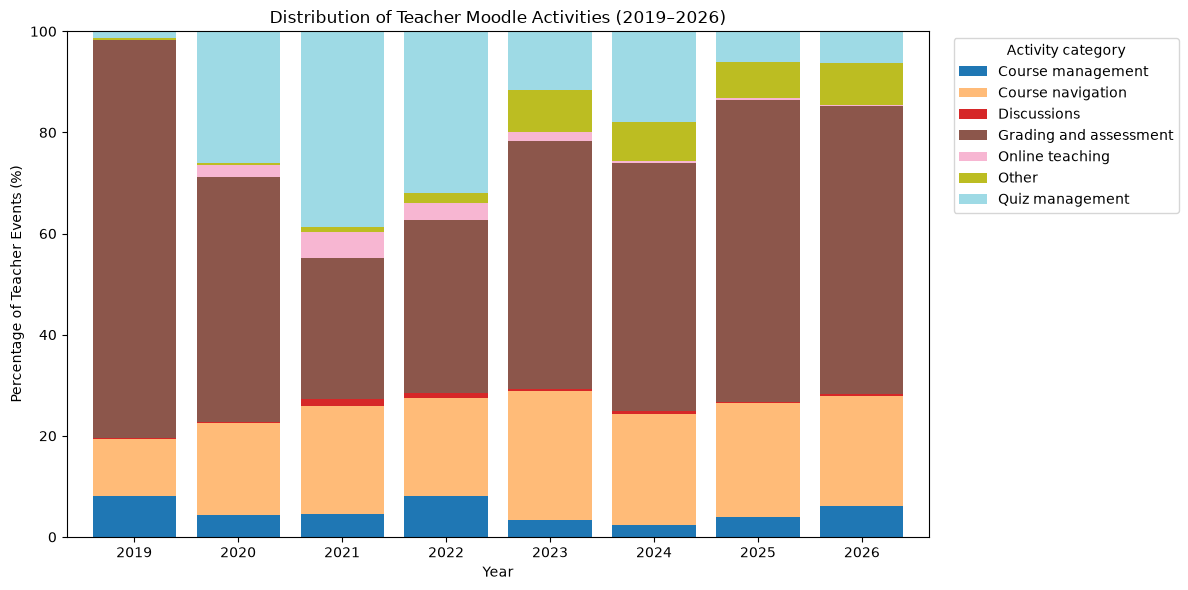

In [38]:
# Visualise teacher activity categories
ax = teacher_category_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20",
    width=0.8
)

plt.title("Distribution of Teacher Moodle Activities (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Percentage of Teacher Events (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.legend(
    title="Activity category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### Interpretation

Grading and assessment dominated teachers' recorded activity in 2019 and 2025–2026, while quiz management represented a larger share during 2020–2022. Online-teaching events were more prominent during the remote-teaching period, and discussion events remained a small share throughout.

The next chart checks the frequency of these categories per teacher, rather than their percentage of total events.

#### Teacher activity categories per teacher

Percentages show how teacher Moodle activity was distributed, but they do not show the frequency of individual activity categories.

We calculate the average number of events in each category per teacher to account for differences in teaching staff size across years.

In [39]:
# Calculate activity-category events per teacher
teacher_category_per_teacher = teacher_category_counts.div(
    teacher_counts,
    axis=0
)

display(teacher_category_per_teacher.round(1))

activity_category,Course management,Course navigation,Discussions,Grading and assessment,Online teaching,Other,Quiz management
year,,,,,,,
2019,217.7,306.6,6.1,2139.9,0.0,14.6,34.6
2020,192.0,818.0,13.7,2174.8,103.0,16.3,1169.3
2021,220.7,1019.0,62.1,1337.0,243.9,44.0,1854.6
2022,252.4,607.7,30.6,1074.6,106.7,57.0,1004.6
2023,135.9,1035.2,21.5,1990.8,76.1,337.5,471.1
2024,109.2,977.0,29.9,2194.9,14.6,353.2,798.8
2025,217.5,1225.2,13.5,3262.8,14.0,394.5,328.7
2026,316.5,1098.3,20.5,2905.5,10.7,423.0,317.2


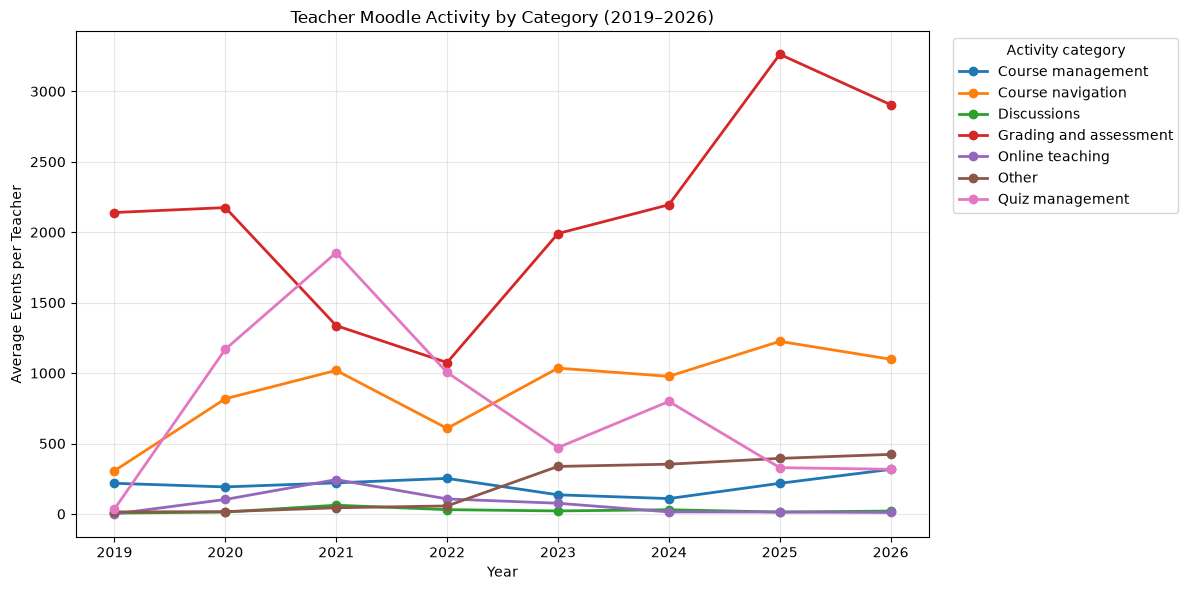

In [40]:
# Visualise activity frequency by category
ax = teacher_category_per_teacher.plot(
    kind="line",
    marker="o",
    figsize=(12, 6),
    linewidth=2
)

plt.title("Teacher Moodle Activity by Category (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Average Events per Teacher")
plt.xticks(teacher_category_per_teacher.index)
plt.grid(alpha=0.3)

plt.legend(
    title="Activity category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### Interpretation

Grading and assessment events per teacher fell to 1,074.6 in 2022 and then rose to 3,262.8 in 2025. Quiz-management events peaked earlier, at 1,854.6 per teacher in 2021, before declining.

Course navigation became more frequent than in 2019, while online-teaching events peaked in 2021. Teacher activity thus changed by category, rather than uniformly across all kinds of work.

### 4.3 Student and teacher activity: main comparison

Students' recorded activity shifted strongly toward quiz interactions in 2021–2024, then back toward a greater share of navigation and assignment events in 2025–2026. Quiz participation nevertheless remained consistently high. Teacher quiz-management activity peaked earlier, in 2021, whereas grading and assessment events per teacher peaked in 2025.

The two groups therefore show distinct activity patterns. The next notebook examines individual events and assessment dates to explain these differences in more detail.

**Classification limitations:** Activity categories were created using Moodle event names. Some events may be generated automatically, and the meaning or frequency of individual events may differ between Moodle versions. Therefore, the categories describe recorded Moodle interactions rather than directly measuring student engagement or teacher workload.